# 02 · The full run — what it cost and what de-duplication saved

`outputs-replica/` is the crawler run end to end: crawl → download → SHA-256 →
de-duplicate → hardlink → report → resume, with real bytes over HTTP against a
local replica that speaks all six listing dialects. 39 documents, 5.1 MiB
downloaded, 9 duplicates collapsed, 1.4 MiB never fetched.

This notebook is about **cost**: bytes on the wire, time per document, and which
de-duplication path handled each collapse.

In [1]:
import os
import sys

# Make the shared loader importable whether the kernel started in the repo root
# or in notebooks/.
CWD = os.getcwd()
for _cand in (os.path.join(CWD, "notebooks"), CWD, os.path.dirname(CWD)):
    if os.path.isfile(os.path.join(_cand, "dadosabertos_data.py")):
        sys.path.insert(0, _cand)
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

import dadosabertos_data as d

plt = d.setup_plots()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 70)

print("repository root :", d.ROOT)
print("loader module   :", os.path.dirname(d.__file__))
for _t in d.TREES:
    print(f"  {_t:<16} {len(d.site_dirs(_t))} site folders")

repository root : /home/user/dadosabertos
loader module   : /home/user/dadosabertos/notebooks
  outputs          5 site folders
  outputs-replica  6 site folders


In [2]:
run = d.load_manifest("outputs-replica")
summary = d.load_summary("outputs-replica").sort_values("documents_discovered", ascending=False)
dups = d.load_duplicates("outputs-replica")

tbl = summary.set_index("site")[
    [
        "documents_discovered",
        "documents_fetched",
        "duplicates",
        "status_downloaded",
        "status_duplicate",
        "bytes_downloaded_this_run",
        "duplicate_bytes_collapsed",
        "documents_bytes",
        "errors",
    ]
].copy()
for col, pretty in (
    ("bytes_downloaded_this_run", "downloaded"),
    ("duplicate_bytes_collapsed", "collapsed"),
    ("documents_bytes", "stored total"),
):
    tbl[pretty] = tbl[col].map(d.human_bytes)
display(tbl[["documents_discovered", "documents_fetched", "duplicates", "downloaded", "collapsed", "stored total", "errors"]])

print(
    f"{len(run)} manifest rows · {int(summary['documents_fetched'].sum())} fetched · "
    f"{int(summary['duplicates'].sum())} collapsed · "
    f"{d.human_bytes(summary['bytes_downloaded_this_run'].sum())} on the wire · "
    f"{d.human_bytes(summary['duplicate_bytes_collapsed'].sum())} saved"
)

,documents_discovered,documents_fetched,duplicates,downloaded,collapsed,stored total,errors
site,,,,,,,
comissaodaverdade.al.sp.gov.br,8,8,2,747.0 KiB,121.0 KiB,626.0 KiB,0
valiprev.sp.gov.br,8,8,2,2.1 MiB,7.4 KiB,2.1 MiB,0
dadosabertos.pgfn.gov.br,7,7,3,1.1 MiB,1.0 MiB,1.1 MiB,0
geofiles.caxias.rs.gov.br,6,6,0,482.3 KiB,0 B,482.3 KiB,0
dados.cvm.gov.br,5,5,1,403.0 KiB,96.0 KiB,307.0 KiB,0
macau.rn.gov.br,5,5,1,690.0 KiB,150.0 KiB,540.0 KiB,0


39 manifest rows · 39 fetched · 9 collapsed · 5.5 MiB on the wire · 1.4 MiB saved


## 1 · What happened to every document

`downloaded` = a fresh payload was fetched and stored. `duplicate` = the crawler
recognised the bytes it already had, stored (by default) a hard link to the kept
copy and recorded the collapse. Nothing is ever silently dropped.

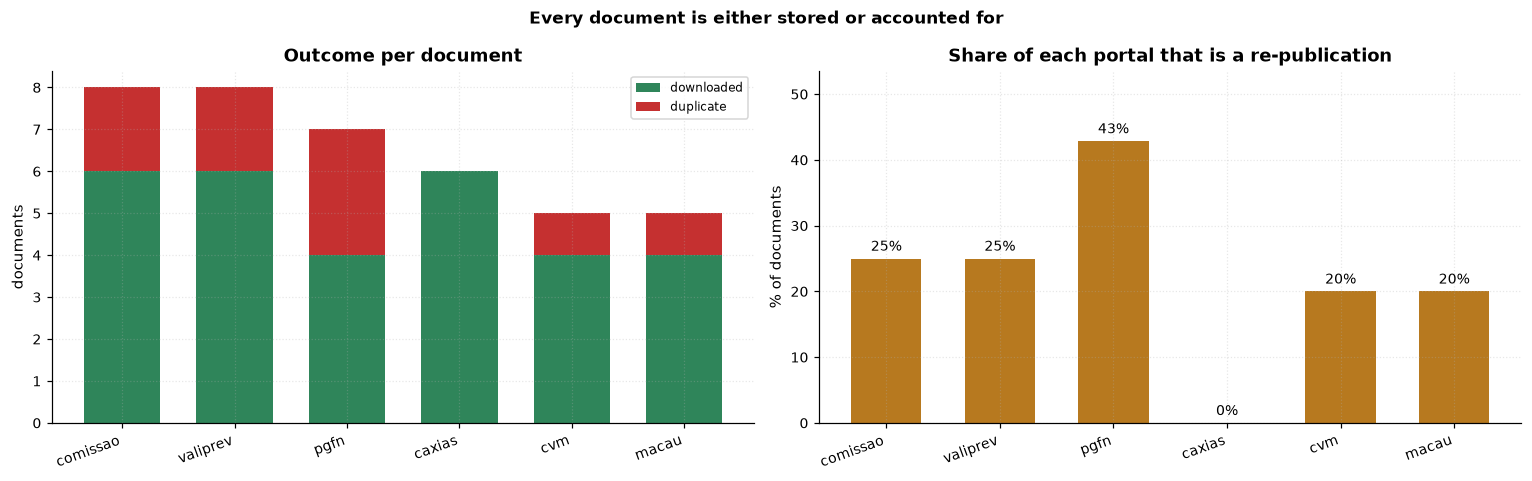

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))

status = pd.crosstab(run["site"], run["status"]).loc[summary["site"]]
bottom = None
for col in status.columns:
    vals = status[col].to_numpy(dtype=float)
    axes[0].bar(
        range(len(status)),
        vals,
        bottom=bottom,
        label=col,
        color={"downloaded": "#2f855a", "duplicate": "#c53030"}.get(col, "#4c51bf"),
        width=0.68,
    )
    bottom = vals if bottom is None else bottom + vals
axes[0].set_xticks(range(len(status)))
axes[0].set_xticklabels([d.short_site(s) for s in status.index], rotation=20, ha="right")
axes[0].set_ylabel("documents")
axes[0].set_title("Outcome per document")
axes[0].legend(fontsize=8)

rate = (status.get("duplicate", 0) / status.sum(axis=1) * 100).fillna(0)
bars = axes[1].bar(range(len(rate)), rate.to_numpy(dtype=float), color="#b7791f", width=0.62)
axes[1].bar_label(bars, labels=[f"{v:.0f}%" for v in rate], padding=3, fontsize=9)
axes[1].set_xticks(range(len(rate)))
axes[1].set_xticklabels([d.short_site(s) for s in rate.index], rotation=20, ha="right")
axes[1].set_ylabel("% of documents")
axes[1].set_title("Share of each portal that is a re-publication")
axes[1].set_ylim(0, max(rate.max(), 1) * 1.25)

fig.suptitle("Every document is either stored or accounted for", fontweight="bold")
fig.tight_layout()
plt.show()

## 2 · Bytes: what came over the wire versus what was recognised

The blue bar is what the run actually downloaded. The red bar is the payload it
did **not** fetch because the bytes were already stored — the whole point of the
SHA-256 index.

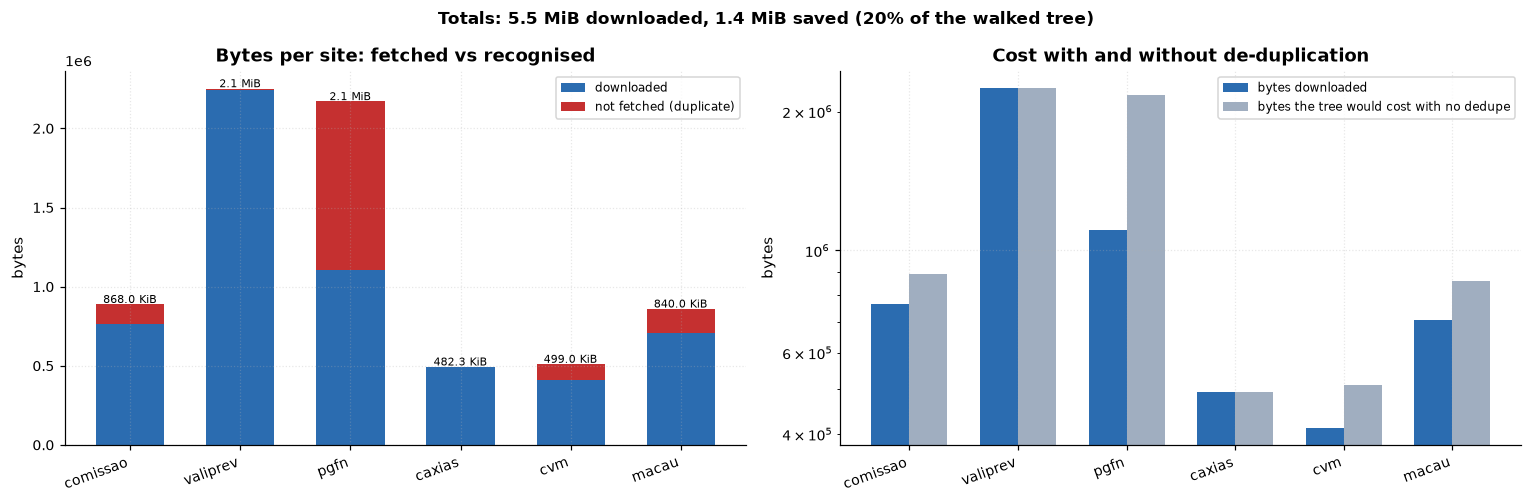

In [4]:
sites = list(summary["site"])
x = range(len(sites))
down = summary["bytes_downloaded_this_run"].to_numpy(dtype=float)
saved = summary["duplicate_bytes_collapsed"].to_numpy(dtype=float)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

axes[0].bar(x, down, 0.62, label="downloaded", color="#2b6cb0")
axes[0].bar(x, saved, 0.62, bottom=down, label="not fetched (duplicate)", color="#c53030")
axes[0].set_xticks(list(x))
axes[0].set_xticklabels([d.short_site(s) for s in sites], rotation=20, ha="right")
axes[0].set_ylabel("bytes")
axes[0].set_title("Bytes per site: fetched vs recognised")
axes[0].legend(fontsize=8)
for i, (a, b) in enumerate(zip(down, saved)):
    axes[0].text(i, a + b + 8000, d.human_bytes(a + b), ha="center", fontsize=7.5)

w = 0.35
axes[1].bar([i - w / 2 for i in x], down, w, label="bytes downloaded", color="#2b6cb0")
axes[1].bar(
    [i + w / 2 for i in x],
    down + saved,
    w,
    label="bytes the tree would cost with no dedupe",
    color="#a0aec0",
)
axes[1].set_xticks(list(x))
axes[1].set_xticklabels([d.short_site(s) for s in sites], rotation=20, ha="right")
axes[1].set_ylabel("bytes")
axes[1].set_yscale("log")
axes[1].set_title("Cost with and without de-duplication")
axes[1].legend(fontsize=8)

fig.suptitle(
    f"Totals: {d.human_bytes(down.sum())} downloaded, {d.human_bytes(saved.sum())} saved "
    f"({saved.sum() / (down.sum() + saved.sum()):.0%} of the walked tree)",
    fontweight="bold",
)
fig.tight_layout()
plt.show()

## 2b · Reconciling the two byte totals

The README quotes 5.1 MiB downloaded and 1.4 MiB saved. Those two numbers come
from different places, and the gap between them is the interesting part:

* **stored** — bytes that ended up kept on disk (`documents_bytes`, also what
  `global.json → bytes_downloaded` reports): 5.1 MiB
* **fetched then collapsed** — duplicates that had to be downloaded once so their
  full SHA-256 could be compared: 374 KiB
* **never fetched** — duplicates the range probe recognised from 128 KiB of
  head/tail: 1.0 MiB

Only the last of those three is traffic you actually avoid.

bucket,bytes,meaning,human
stored once,5345336.000000,kept on disk; what global.json calls bytes_downloaded,5.1 MiB
"fetched, then collapsed by sha256",383408.000000,had to be downloaded to be proved identical,374.4 KiB
never fetched (range probe),1064960.000000,recognised from 2 × 64 KiB — the real saving,1.0 MiB
tree walked,6793704.000000,what a mirror with no de-duplication would have transferred,6.5 MiB
bytes on the wire,5728744.000000,stored + fetched-then-collapsed,5.5 MiB


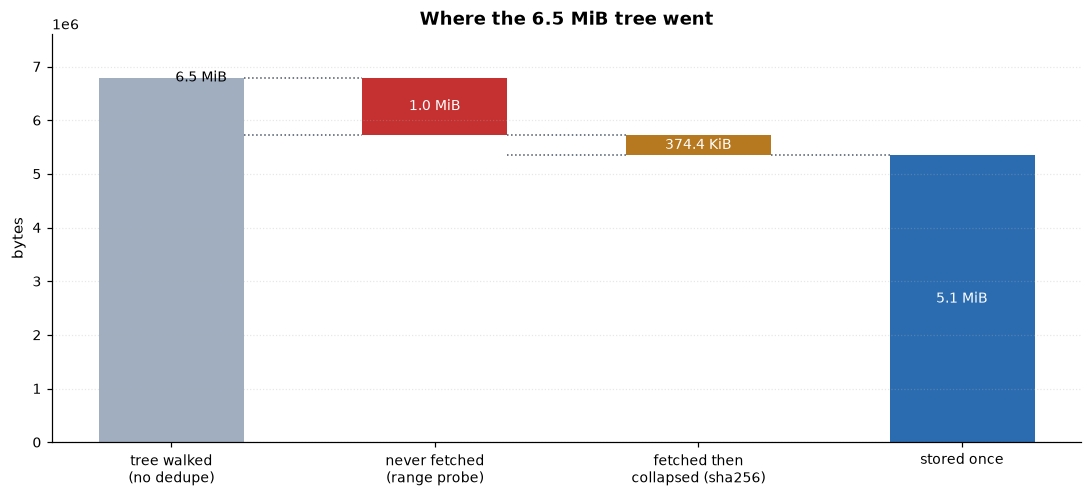

traffic actually avoided: 1.0 MiB = 15.7% of the tree
payload recognised as duplicate: 1.4 MiB = 21.3% of the tree
of that, 26% still crossed the network before it was collapsed


In [5]:
stored_b = float(summary["documents_bytes"].sum())
fetched_dup = float(dups.loc[dups["method"] == "sha256", "size"].sum())
never_b = float(dups.loc[dups["method"] == "range-probe", "size"].sum())
wire = stored_b + fetched_dup
tree = stored_b + fetched_dup + never_b

assert abs(wire - float(summary["bytes_downloaded_this_run"].sum())) < 1, "byte accounting broke"
assert abs(stored_b - d.load_global("outputs-replica")["totals"]["bytes_downloaded"]) < 1

recon = pd.DataFrame(
    [
        ("stored once", stored_b, "kept on disk; what global.json calls bytes_downloaded"),
        ("fetched, then collapsed by sha256", fetched_dup, "had to be downloaded to be proved identical"),
        ("never fetched (range probe)", never_b, "recognised from 2 × 64 KiB — the real saving"),
        ("tree walked", tree, "what a mirror with no de-duplication would have transferred"),
        ("bytes on the wire", wire, "stored + fetched-then-collapsed"),
    ],
    columns=["bucket", "bytes", "meaning"],
)
recon["human"] = recon["bytes"].map(d.human_bytes)
display(recon.style.hide(axis="index"))

fig, ax = plt.subplots(figsize=(10, 4.6))
labels = [
    "tree walked\n(no dedupe)",
    "never fetched\n(range probe)",
    "fetched then\ncollapsed (sha256)",
    "stored once",
]
ax.bar(0, tree, 0.55, color="#a0aec0")
ax.text(0, tree, " " + d.human_bytes(tree), va="center", fontsize=9)
ax.bar(1, never_b, 0.55, bottom=tree - never_b, color="#c53030")
ax.text(1, tree - never_b / 2, d.human_bytes(never_b), ha="center", va="center", color="white", fontsize=9)
ax.bar(2, fetched_dup, 0.55, bottom=stored_b, color="#b7791f")
ax.text(2, stored_b + fetched_dup / 2, d.human_bytes(fetched_dup), ha="center", va="center", color="white", fontsize=9)
ax.bar(3, stored_b, 0.55, color="#2b6cb0")
ax.text(3, stored_b / 2, d.human_bytes(stored_b), ha="center", va="center", color="white", fontsize=9)

# connector lines
for x0, y0, x1, y1 in (
    (0.275, tree, 0.725, tree),
    (0.275, tree - never_b, 0.725, tree - never_b),
    (1.275, tree - never_b, 1.725, tree - never_b),
    (1.275, stored_b, 1.725, stored_b),
    (2.275, stored_b, 2.725, stored_b),
):
    ax.plot([x0, x1], [y0, y1], ls=":", color="#4a5568", lw=1)

ax.set_xticks(range(4))
ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel("bytes")
ax.set_title("Where the 6.5 MiB tree went")
ax.set_ylim(0, tree * 1.12)
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

print(f"traffic actually avoided: {d.human_bytes(never_b)} = {never_b / tree:.1%} of the tree")
print(f"payload recognised as duplicate: {d.human_bytes(never_b + fetched_dup)} = "
      f"{(never_b + fetched_dup) / tree:.1%} of the tree")
print(f"of that, {fetched_dup / (never_b + fetched_dup):.0%} still crossed the network before it was collapsed")

## 3 · Which de-duplication path decided each collapse?

Two methods appear in `duplicates.csv`:

* **`sha256`** — the candidate was downloaded once and compared by full-content
  digest. Exact, but it costs a full download.
* **`range-probe`** — the listing published the same size, so the crawler sent
  two single-range requests (first and last 64 KiB) and treated an identical
  head *and* tail as a strong heuristic. Costs 128 KiB instead of the whole file.

The probe is a heuristic, not a proof: two files of the same size can differ in
the middle. That is why the method is recorded per row and why
`--no-range-probe` exists.

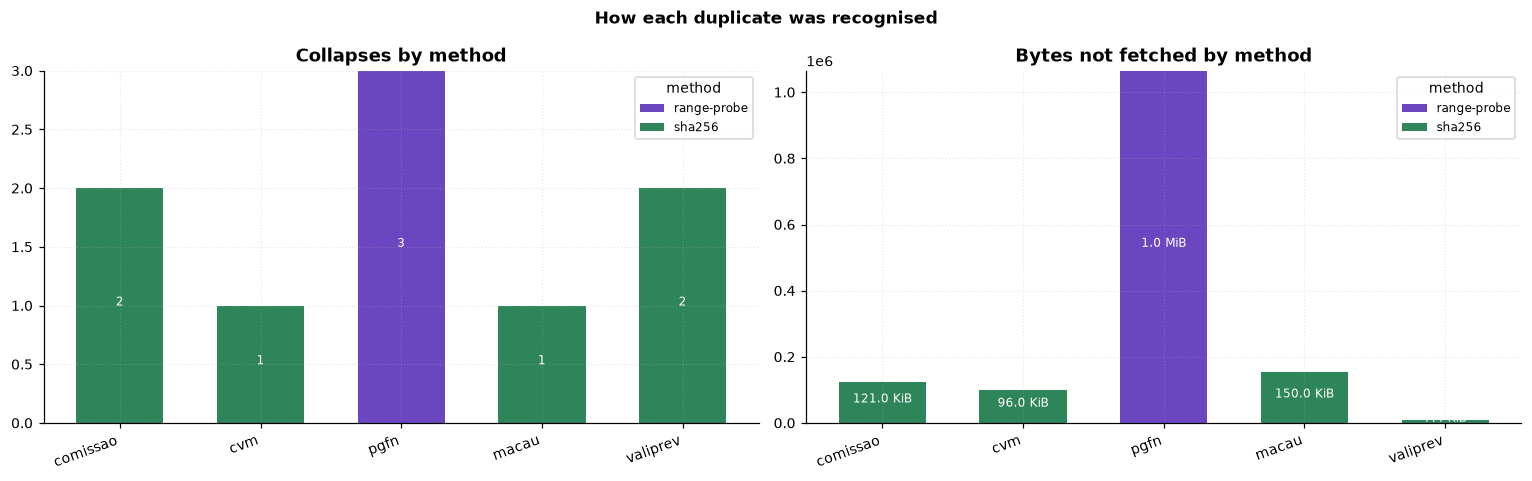

,site,method,size,kept,duplicate,action
0,comissaodaverdade.al.sp.gov.br,sha256,88.0 KiB,001-Arquivo-CEMDP-Joao-Carlos-Cavalcanti-Reis.pdf,001-Arquivo-CEMDP-Joao-Carlos-Cavalcanti-Reis004.pdf,stored as hardlink
1,comissaodaverdade.al.sp.gov.br,sha256,33.0 KiB,001-ArquivoCEMDP-devanir.pdf,001-ArquivoCEMDP.pdf,stored as hardlink
2,dados.cvm.gov.br,sha256,96.0 KiB,cia_aberta_doc_2025.zip,fidc_doc_2025.zip,stored as hardlink
3,dadosabertos.pgfn.gov.br,range-probe,300.0 KiB,Dados_abertos_FGTS.zip,Dados_abertos_FGTS.zip,stored as hardlink
4,dadosabertos.pgfn.gov.br,range-probe,320.0 KiB,Dados_abertos_Nao_Previdenciario.zip,Dados_abertos_Nao_Previdenciario.zip,stored as hardlink
5,dadosabertos.pgfn.gov.br,range-probe,420.0 KiB,Dados_abertos_Previdenciario.zip,Dados_abertos_Previdenciario.zip,stored as hardlink
6,macau.rn.gov.br,sha256,150.0 KiB,macau-2013-01-02.pdf,macau-2013-03-11-edicao-2.pdf,stored as hardlink
7,valiprev.sp.gov.br,sha256,3.7 KiB,10_2023-LGPD-ARTE-VISUAL-E-IMPRESSAO-DAS-ELEICOES-DO-CONSELHO-DISP...,10_2023-LGPD-ARTE-VISUAL-E-IMPRESSAO-DAS-ELEICOES-DO-CONSELHO-DISP...,stored as hardlink
8,valiprev.sp.gov.br,sha256,3.7 KiB,10_2023-LGPD-ARTE-VISUAL-E-IMPRESSAO-DAS-ELEICOES-DO-CONSELHO-DISP...,10_2023-LGPD-ARTE-VISUAL-E-IMPRESSAO-DAS-ELEICOES-DO-CONSELHO-DISP...,stored as hardlink


In [6]:
method = (
    dups.groupby(["site", "method"])
    .agg(collapses=("size", "count"), bytes=("size", "sum"))
    .reset_index()
)
piv_c = method.pivot(index="site", columns="method", values="collapses").fillna(0)
piv_b = method.pivot(index="site", columns="method", values="bytes").fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for ax, piv, title, fmt in (
    (axes[0], piv_c, "Collapses by method", lambda v: str(int(v))),
    (axes[1], piv_b, "Bytes not fetched by method", d.human_bytes),
):
    bottom = None
    for col in piv.columns:
        vals = piv[col].to_numpy(dtype=float)
        ax.bar(
            range(len(piv)),
            vals,
            bottom=bottom,
            label=col,
            color={"sha256": "#2f855a", "range-probe": "#6b46c1"}.get(col, "#4c51bf"),
            width=0.62,
        )
        for i, v in enumerate(vals):
            if v > 0:
                ax.text(i, (bottom[i] if bottom is not None else 0) + v / 2, fmt(v), ha="center", fontsize=8, color="white")
        bottom = vals if bottom is None else bottom + vals
    ax.set_xticks(range(len(piv)))
    ax.set_xticklabels([d.short_site(s) for s in piv.index], rotation=20, ha="right")
    ax.set_title(title)
    ax.legend(fontsize=8, title="method")

fig.suptitle("How each duplicate was recognised", fontweight="bold")
fig.tight_layout()
plt.show()

display(
    dups.assign(
        size=dups["size"].map(d.human_bytes),
        kept=dups["kept_url"].str.rsplit("/", n=1).str[-1],
        duplicate=dups["duplicate_path"].str.rsplit("/", n=1).str[-1],
    )[["site", "method", "size", "kept", "duplicate", "action"]]
    .sort_values(["site", "method"])
    .reset_index(drop=True)
)

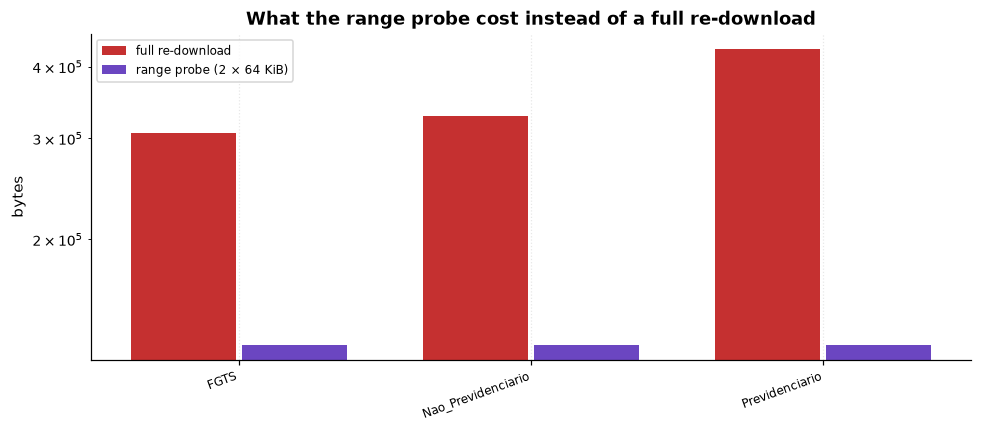

,site,duplicate_path,full,probe,saved
0,dadosabertos.pgfn.gov.br,2025_trimestre_04/Dados_abertos_FGTS.zip,300.0 KiB,128.0 KiB,172.0 KiB
1,dadosabertos.pgfn.gov.br,2025_trimestre_04/Dados_abertos_Nao_Previdenciario.zip,320.0 KiB,128.0 KiB,192.0 KiB
2,dadosabertos.pgfn.gov.br,2025_trimestre_04/Dados_abertos_Previdenciario.zip,420.0 KiB,128.0 KiB,292.0 KiB


probe spent 384.0 KiB to avoid 1.0 MiB of transfers (63.1% less traffic on those files)


In [7]:
PROBE_BYTES = 2 * 64 * 1024  # two single-range requests of 64 KiB each

probe = dups[dups["method"] == "range-probe"].copy()
probe["probe_cost"] = PROBE_BYTES
probe["full_cost"] = probe["size"]

fig, ax = plt.subplots(figsize=(9, 4))
x = range(len(probe))
ax.bar([i - 0.19 for i in x], probe["full_cost"], 0.36, label="full re-download", color="#c53030")
ax.bar([i + 0.19 for i in x], probe["probe_cost"], 0.36, label="range probe (2 × 64 KiB)", color="#6b46c1")
ax.set_yscale("log")
ax.set_xticks(list(x))
ax.set_xticklabels(
    [n.replace(".zip", "").replace("Dados_abertos_", "") for n in probe["duplicate_path"].str.rsplit("/", n=1).str[-1]],
    rotation=20,
    ha="right",
    fontsize=8,
)
ax.set_ylabel("bytes")
ax.set_title("What the range probe cost instead of a full re-download")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

display(probe.assign(
    full=probe["full_cost"].map(d.human_bytes),
    probe=probe["probe_cost"].map(d.human_bytes),
    saved=probe["size"].sub(PROBE_BYTES).map(d.human_bytes),
)[["site", "duplicate_path", "full", "probe", "saved"]].reset_index(drop=True))

print(
    f"probe spent {d.human_bytes(PROBE_BYTES * len(probe))} to avoid "
    f"{d.human_bytes(probe['size'].sum())} of transfers "
    f"({1 - PROBE_BYTES * len(probe) / probe['size'].sum():.1%} less traffic on those files)"
)

## 4 · Throughput

`duration_s` is the wall time of each individual transfer. On the local replica
it is dominated by request overhead rather than bandwidth, which is exactly why
the range probe matters: on a real WAN link each avoided re-download is worth far
more than these numbers suggest.

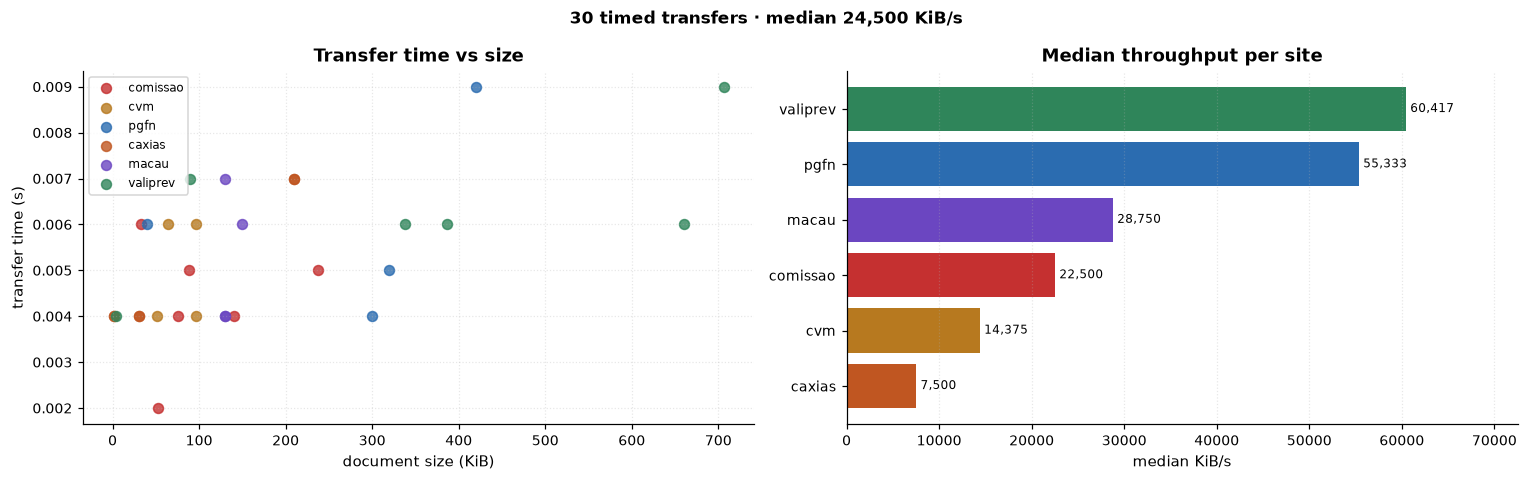

In [8]:
timed = run[run["duration_s"].notna()].copy()
timed["KiB"] = timed["size"] / 1024
timed["KiB/s"] = timed["KiB"] / timed["duration_s"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for site, grp in timed.groupby("site"):
    axes[0].scatter(
        grp["KiB"], grp["duration_s"], s=42, alpha=0.8, label=d.short_site(site), color=d.colors_for([site])[0]
    )
axes[0].set_xlabel("document size (KiB)")
axes[0].set_ylabel("transfer time (s)")
axes[0].set_title("Transfer time vs size")
axes[0].legend(fontsize=8)

speed = timed.groupby("site")["KiB/s"].median().sort_values()
bars = axes[1].barh([d.short_site(s) for s in speed.index], speed.to_numpy(dtype=float), color=d.colors_for(speed.index))
axes[1].bar_label(bars, labels=[f"{v:,.0f}" for v in speed], padding=3, fontsize=8)
axes[1].set_xlabel("median KiB/s")
axes[1].set_title("Median throughput per site")
axes[1].set_xlim(0, speed.max() * 1.2)
axes[1].grid(axis="y", visible=False)

fig.suptitle(
    f"{len(timed)} timed transfers · median {timed['KiB/s'].median():,.0f} KiB/s", fontweight="bold"
)
fig.tight_layout()
plt.show()

## 5 · What was actually stored

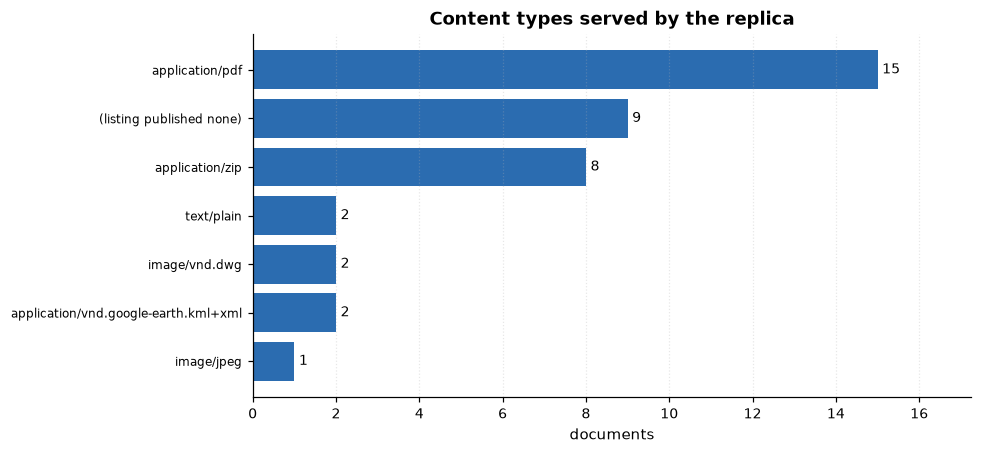

,documents,stored
site,,
comissaodaverdade.al.sp.gov.br,8,747.0 KiB
dados.cvm.gov.br,5,403.0 KiB
dadosabertos.pgfn.gov.br,7,2.1 MiB
geofiles.caxias.rs.gov.br,6,482.3 KiB
macau.rn.gov.br,5,690.0 KiB
valiprev.sp.gov.br,8,2.1 MiB


In [9]:
ct = run["content_type"].fillna("(listing published none)")
counts = ct.value_counts()
fig, ax = plt.subplots(figsize=(9, 4.2))
bars = ax.barh(counts.index[::-1], counts.to_numpy()[::-1], color="#2b6cb0")
ax.bar_label(bars, padding=3, fontsize=9)
ax.set_xlabel("documents")
ax.set_title("Content types served by the replica")
ax.set_xlim(0, counts.max() * 1.15)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
plt.show()

stored = run.groupby("site")["size"].agg(["count", "sum"])
stored["stored"] = stored["sum"].map(d.human_bytes)
display(stored[["count", "stored"]].rename(columns={"count": "documents"}))

## Take-aways

* **9 of 39 documents (23%) were re-publications** the crawler had already seen —
  1.4 MiB of a 6.5 MiB tree.
* Only **1.0 MiB** of that was traffic genuinely avoided: the three PGFN archives
  the range probe caught with two 64 KiB requests each, 63% less traffic on those
  files. That is the single biggest win, and the row set to re-check with
  `--no-range-probe` when byte-exactness matters.
* The other **374 KiB** was downloaded and only then collapsed by full SHA-256 —
  the crawler cannot know two files are identical without either fetching one or
  probing its head and tail.
* Everything decided by **full SHA-256** is exact by construction; zero errors, and
  every document ended up either `downloaded` or `duplicate`.
* Zero errors, and every document ended up either `downloaded` or `duplicate`.